# Phân cụm ngân hàng-quý và PCA

In [1]:
from pathlib import Path
import sys
root = Path.cwd()
if not (root / 'src').exists():
    root = root.parent
sys.path.insert(0, str(root / 'src'))
from utils import *
from IPython.display import display, Image, Markdown


## Objective

Phân cụm 160 quan sát ngân hàng-quý dựa trên 6 financial. Đây là mô tả toàn kỳ, không phải dự báo.

## Load Data và Validate Data

Chỉ tiếp tục sau kiểm tra đạt READY.

In [2]:
from data_validation import run as validate
d, status = validate()
assert status == 'READY FOR ML'

READY FOR ML errors=0


## Preprocessing

Chuẩn hóa toàn bộ 160 mẫu cho phân cụm mô tả; CAR gốc giữ nguyên. Không thêm target/event vào K-Means.

## Model

K=2..6; random_state=42, n_init=auto. Chọn silhouette lớn nhất, đối chiếu inertia và khả năng diễn giải profile. PCA dùng đúng ma trận standardized của K-Means.

In [3]:
from clustering import run
scores, k, profile, variance, loadings, bank = run(d)
print('Chosen K:', k)
for table in [scores, profile, variance, loadings, bank]:
    display(table)

Chosen K: 2


,K,Inertia,Silhouette,smallest_cluster
0,2,611.814819,0.533655,21
1,3,413.216729,0.373781,20
2,4,340.162322,0.356558,18
3,5,283.092439,0.376367,3
4,6,261.265111,0.310470,3


,roa,roe,nim,npl,car,ldr,observations,description
cluster,,,,,,,,
0,1.778996,19.528746,3.613944,1.290670,10.93518,103.310717,139,NPL thấp tương đối / LDR thấp tương đối
1,1.986867,12.810967,6.335367,4.796538,14.66381,134.825324,21,NPL cao tương đối / LDR cao tương đối


,PC,explained_variance_ratio,cumulative
0,PC1,0.499099,0.499099
1,PC2,0.321138,0.820237


,Feature,PC1,PC2
0,roa,0.346046,0.558965
1,roe,-0.024555,0.670951
2,nim,0.505583,0.122141
3,npl,0.357655,-0.444977
4,car,0.495913,-0.002705
5,ldr,0.500188,-0.156372


cluster,0,1
ma_nh,,
ACB,20,0
BID,20,0
CTG,20,0
MBB,20,0
STB,19,1
TCB,20,0
VCB,20,0
VPB,0,20


## Evaluation và Visualization

Điểm PCA là ngân hàng-quý; màu là cụm. Hình 2D chỉ giữ một phần phương sai.

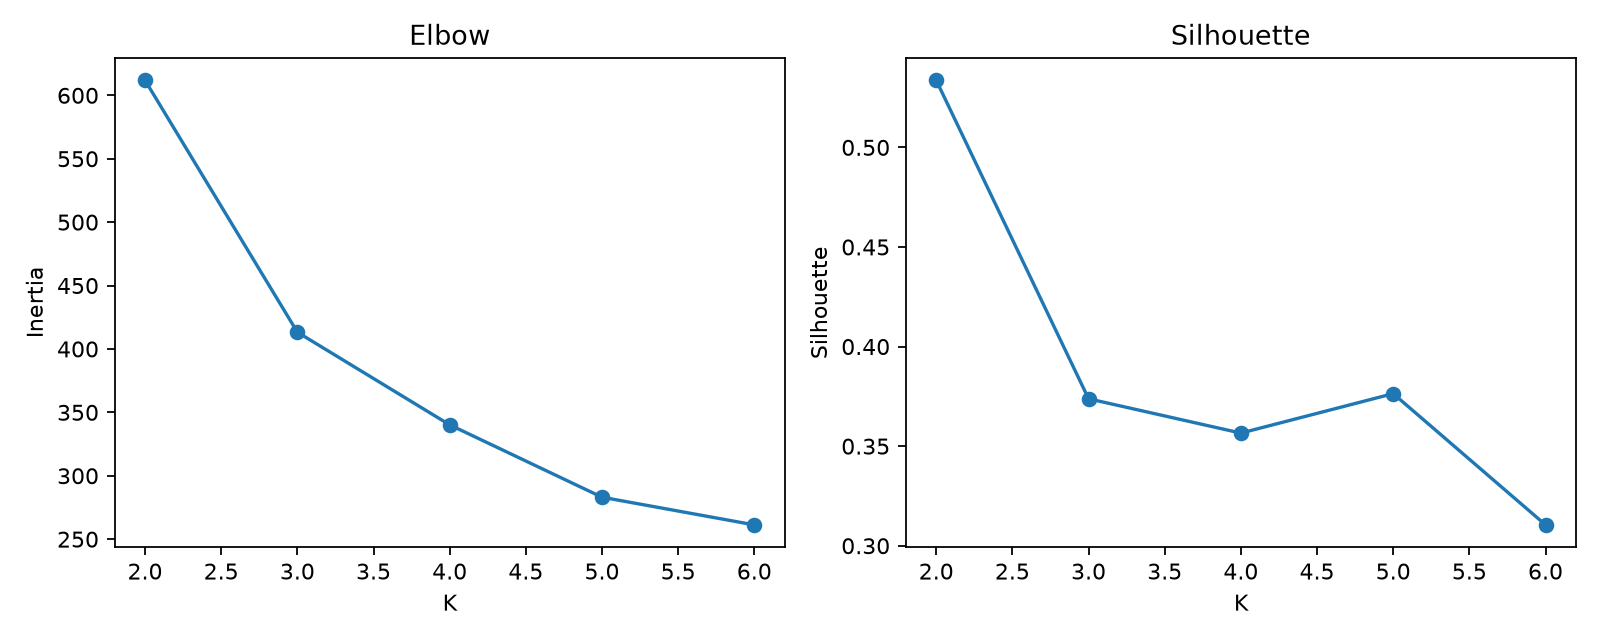

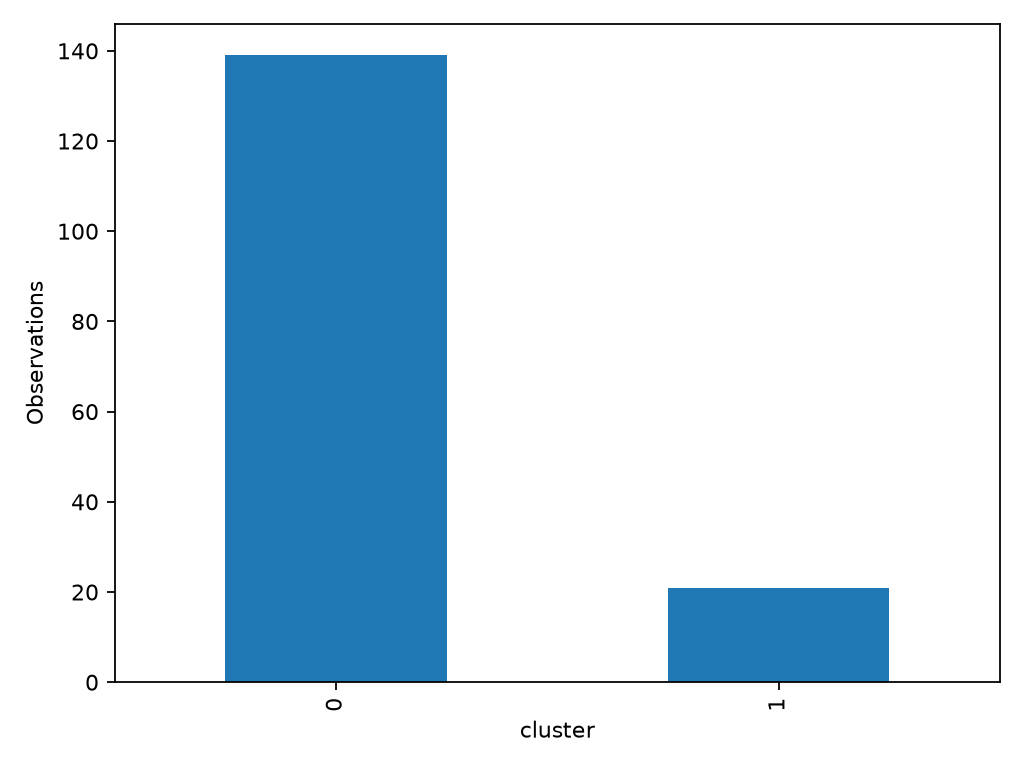

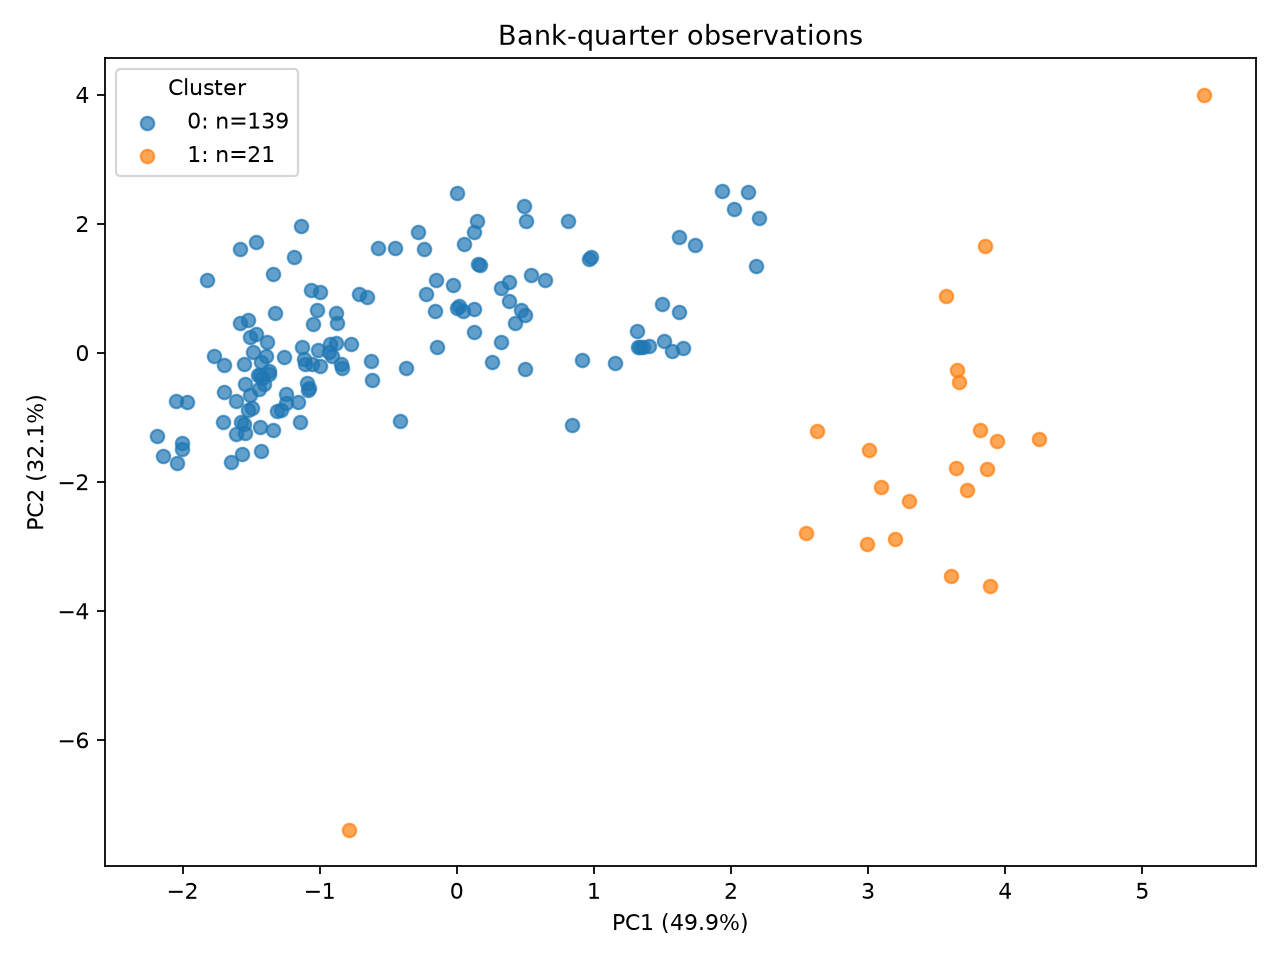

In [4]:
for name in ['k_selection','cluster_distribution','pca_scatter']:
    display(Image(filename=str(FIGURES / f'{name}.png')))

## Interpretation và Conclusion

Đặt tên bằng các độ lệch tương đối lớn nhất sau khi tính profile; không gán nhãn tốt/xấu. Loadings là pca.components_; dấu PC tùy quy ước. Xem bảng ngân hàng, thời gian và chuyển cụm để phân tích sâu.